###                                              Building a CNN Model for Image Classification

In [14]:
import tensorflow as tf

train_path = r"E:\DS13\Entri_Assignments\archive\seg_train\seg_train"

dataset = tf.keras.utils.image_dataset_from_directory(
    train_path,
    image_size=(150, 150)
)

Found 14034 files belonging to 6 classes.


In [15]:
class_names=dataset.class_names

print("Class names:", class_names)
print("Number of classes:", len(class_names))

Class names: ['buildings', 'forest', 'glacier', 'mountain', 'sea', 'street']
Number of classes: 6


buildings (150, 150)


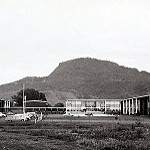

forest (150, 150)


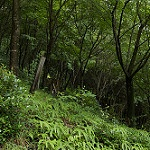

glacier (150, 150)


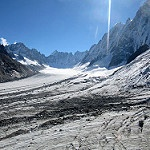

mountain (150, 150)


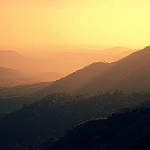

sea (150, 150)


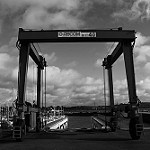

street (150, 150)


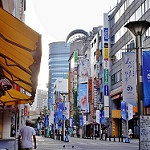

In [16]:
from pathlib import Path
from PIL import Image

for class_name in class_names:
    class_folder = Path(train_path) / class_name
    image_path = next(class_folder.glob("*.jpg"))

    with Image.open(image_path) as photo:
        print(class_name, photo.size)
        display(photo)

In [20]:
def normalize(images, labels):
    return images / 255.0, labels

normalized_data = dataset.map(normalize)

for images, labels in normalized_data.take(1):
    print("Minimum pixel value:", tf.reduce_min(images).numpy())
    print("Maximum pixel value:", tf.reduce_max(images).numpy())

Minimum pixel value: 0.0
Maximum pixel value: 1.0


In [21]:
load_images = tf.keras.utils.image_dataset_from_directory
test_path = Path(train_path).parent.parent / "seg_test" / "seg_test"

train_data, val_data = load_images(
    train_path,
    image_size=(150, 150),
    validation_split=0.20,
    subset="both",
    seed=42
)

test_data = load_images(
    str(test_path),
    image_size=(150, 150),
    class_names=class_names,
    shuffle=False
)

train_data = train_data.map(normalize)
val_data = val_data.map(normalize)
test_data = test_data.map(normalize)

Found 14034 files belonging to 6 classes.
Using 11228 files for training.
Using 2806 files for validation.
Found 3000 files belonging to 6 classes.


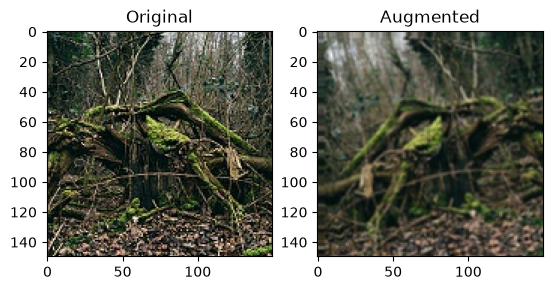

In [22]:
import matplotlib.pyplot as plt

data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomRotation(0.05),
    tf.keras.layers.RandomZoom(0.10),
    tf.keras.layers.RandomTranslation(0.08, 0.08)
])

images, labels = next(iter(train_data))
original = images[:1]
augmented = data_augmentation(original, training=True)

plt.subplot(1, 2, 1)
plt.imshow(original[0])
plt.title("Original")

plt.subplot(1, 2, 2)
plt.imshow(augmented[0])
plt.title("Augmented")

plt.show()

In [23]:
layers = tf.keras.layers

model = tf.keras.Sequential([
    tf.keras.Input(shape=(150, 150, 3)),
    data_augmentation,

    layers.Conv2D(32, (3, 3), padding="same", activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), padding="same", activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(128, (3, 3), padding="same", activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.GlobalAveragePooling2D(),
    layers.Dense(64, activation="relu"),
    layers.Dropout(0.30),
    layers.Dense(len(class_names), activation="softmax")
])

model.summary()


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential (Sequential)         │ (None, 150, 150, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 150, 150, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 75, 75, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 75, 75, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 37, 37, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 37, 37, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 18, 18, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 6)              │           390 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,894 (398.02 KB)

 Trainable params: 101,894 (398.02 KB)

 Non-trainable params: 0 (0.00 B)

In [24]:
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("Model compiled successfully")

Model compiled successfully


In [25]:
early_stop = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

checkpoint = tf.keras.callbacks.ModelCheckpoint(
    "best_intel_cnn.keras",
    monitor="val_loss",
    mode="min",
    save_best_only=True
)

history = model.fit(
    train_data,
    validation_data=val_data,
    epochs=10,
    callbacks=[early_stop, checkpoint]
)

Epoch 1/10


c:\Users\rashi\anaconda3\envs\tf_env\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


351/351 ━━━━━━━━━━━━━━━━━━━━ 292s 815ms/step - accuracy: 0.4275 - loss: 1.3533 - val_accuracy: 0.4134 - val_loss: 1.4551
Epoch 2/10
351/351 ━━━━━━━━━━━━━━━━━━━━ 229s 651ms/step - accuracy: 0.5223 - loss: 1.1367 - val_accuracy: 0.5706 - val_loss: 1.1412
Epoch 3/10
351/351 ━━━━━━━━━━━━━━━━━━━━ 228s 650ms/step - accuracy: 0.5668 - loss: 1.0670 - val_accuracy: 0.6144 - val_loss: 0.9825
Epoch 4/10
351/351 ━━━━━━━━━━━━━━━━━━━━ 235s 668ms/step - accuracy: 0.6073 - loss: 1.0002 - val_accuracy: 0.5310 - val_loss: 1.1741
Epoch 5/10
351/351 ━━━━━━━━━━━━━━━━━━━━ 229s 653ms/step - accuracy: 0.6263 - loss: 0.9525 - val_accuracy: 0.6458 - val_loss: 0.8704
Epoch 6/10
351/351 ━━━━━━━━━━━━━━━━━━━━ 229s 652ms/step - accuracy: 0.6545 - loss: 0.8995 - val_accuracy: 0.7145 - val_loss: 0.7650
Epoch 7/10
351/351 ━━━━━━━━━━━━━━━━━━━━ 172s 488ms/step - accuracy: 0.6714 - loss: 0.8747 - val_accuracy: 0.7177 - val_loss: 0.7414
Epoch 8/10
351/351 ━━━━━━━━━━━━━━━━━━━━ 174s 497ms/step - accuracy: 0.6967 - loss: 0.80

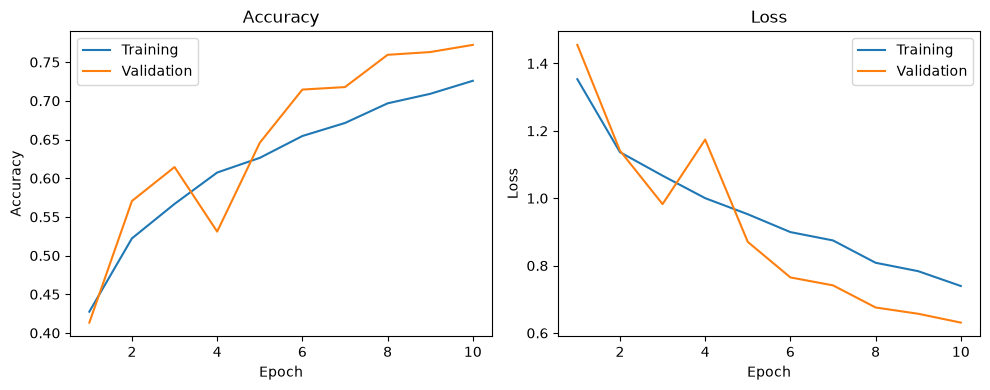

In [26]:
scores = history.history
epoch_numbers = range(1, len(scores["loss"]) + 1)

plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.plot(epoch_numbers, scores["accuracy"], label="Training")
plt.plot(epoch_numbers, scores["val_accuracy"], label="Validation")
plt.title("Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(epoch_numbers, scores["loss"], label="Training")
plt.plot(epoch_numbers, scores["val_loss"], label="Validation")
plt.title("Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()

In [27]:
best_model = tf.keras.models.load_model("best_intel_cnn.keras")

test_results = best_model.evaluate(test_data, return_dict=True)

print(f"Test accuracy: {test_results['accuracy']:.2%}")
print(f"Test loss: {test_results['loss']:.4f}")

94/94 ━━━━━━━━━━━━━━━━━━━━ 16s 161ms/step - accuracy: 0.7643 - loss: 0.6345
Test accuracy: 76.43%
Test loss: 0.6345


In [28]:
import numpy as np
from sklearn.metrics import classification_report

probabilities = best_model.predict(test_data, verbose=0)
predicted_labels = np.argmax(probabilities, axis=1)

actual_labels = np.concatenate([
    labels.numpy() for images, labels in test_data
])

print(classification_report(
    actual_labels,
    predicted_labels,
    labels=range(len(class_names)),
    target_names=class_names,
    zero_division=0
))

              precision    recall  f1-score   support

   buildings       0.84      0.57      0.68       437
      forest       0.92      0.95      0.94       474
     glacier       0.77      0.67      0.72       553
    mountain       0.70      0.74      0.72       525
         sea       0.71      0.80      0.75       510
      street       0.70      0.84      0.77       501

    accuracy                           0.76      3000
   macro avg       0.77      0.76      0.76      3000
weighted avg       0.77      0.76      0.76      3000



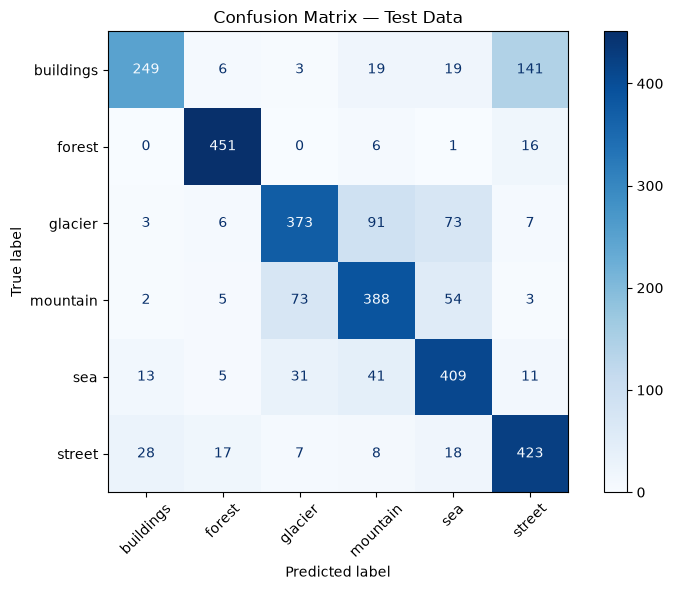

In [29]:
from sklearn.metrics import ConfusionMatrixDisplay

_, ax = plt.subplots(figsize=(8, 6))

ConfusionMatrixDisplay.from_predictions(
    actual_labels,
    predicted_labels,
    labels=range(len(class_names)),
    display_labels=class_names,
    cmap="Blues",
    xticks_rotation=45,
    ax=ax
)

ax.set_title("Confusion Matrix — Test Data")
plt.tight_layout()
plt.show()

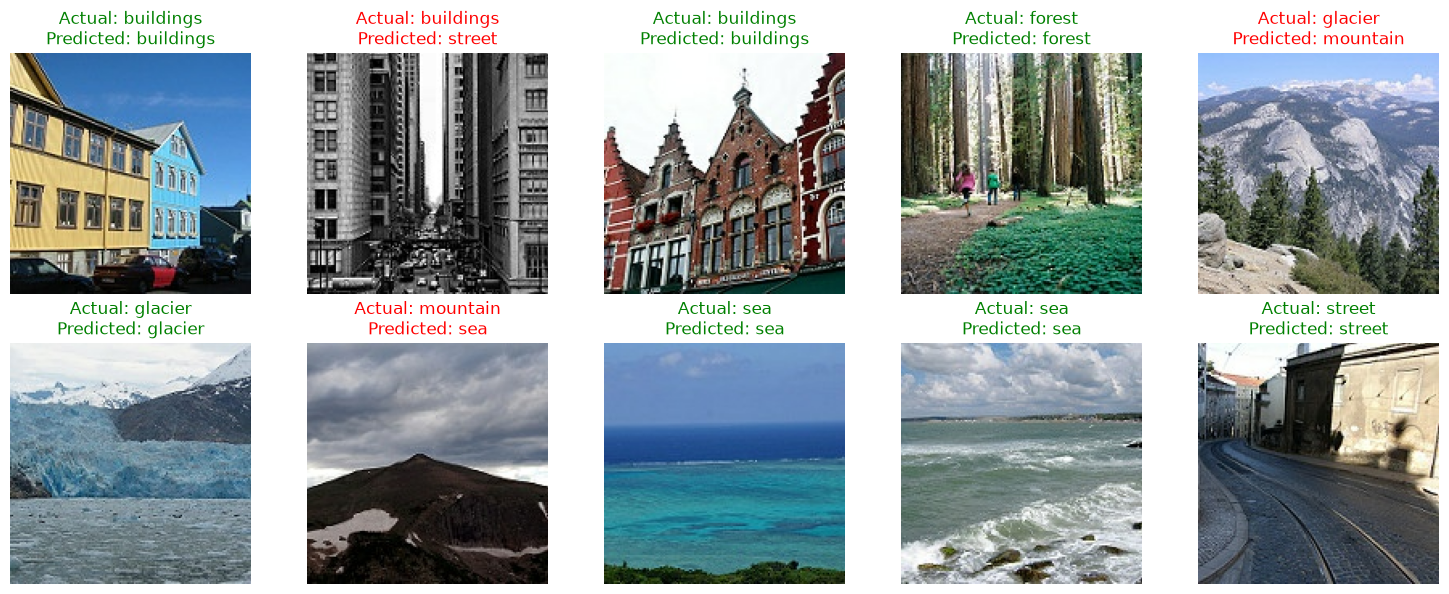

In [30]:
rng = np.random.default_rng(42)
selected_indices = set(
    rng.choice(len(actual_labels), size=10, replace=False)
)

_, axes = plt.subplots(2, 5, figsize=(15, 6))
plot_number = 0

for index, (photo, label) in enumerate(test_data.unbatch()):
    if index in selected_indices:
        actual = class_names[actual_labels[index]]
        predicted = class_names[predicted_labels[index]]
        color = "green" if actual == predicted else "red"

        ax = axes.flat[plot_number]
        ax.imshow(photo)
        ax.set_title(f"Actual: {actual}\nPredicted: {predicted}", color=color)
        ax.axis("off")

        plot_number += 1
        if plot_number == 10:
            break

plt.tight_layout()
plt.show()